In [1]:
# Setup: run this cell first (needed on Google Colab; harmless elsewhere).
# Versions are pinned to the ones this workbook was tested with.
%pip install -q "qiskit==2.6.2" "qiskit-aer==0.18.4" "pylatexenc==2.11"

Note: you may need to restart the kernel to use updated packages.


# Workbook 4: Multiple Qubits

**Quantum Computing Course, Workbook 4 of 14.** Prepared by Aditya Sharma.

This workbook moves from one qubit to two. You will meet the CNOT gate, the four Bell states and entanglement, and learn what a histogram can and cannot tell you about it. Run the setup cell above first.

# How to use this workbook

Part A has the theory notes, Part B the exercises (easy, medium, hard, then Qiskit tasks) and Part C the answer key (instructor edition only). You need Workbook 1 (tensor product preview), Workbook 2 (Born rule, X-basis measurement, shot statistics) and Workbook 3 (single-qubit gates, `Operator`, `Statevector`).

> **Note.** Boxes marked **Note** give tips and context. Boxes marked **Common mistake** flag errors that students make often.

## Learning outcomes

By the end of this workbook you should be able to:

1. Write two-qubit states as vectors in $\mathbb{C}^4$ using the tensor product, in the qubit ordering used by Qiskit.
2. Apply single-qubit gates and the CNOT gate to two-qubit states, by hand and as $4\times4$ matrices.
3. Prepare the four Bell states with a circuit and check them in Qiskit.
4. Decide whether a two-qubit pure state is a product state or entangled.
5. Compute probabilities and post-measurement states when only one qubit is measured.
6. Explain why a Z-basis histogram alone cannot distinguish entanglement from classical correlation, and use Z- and X-basis correlations to tell them apart.

# Part A: Theory notes

## 4.1 Two-qubit states

Two qubits together have four basis states, one for each pair of bit values. Their state lives in $\mathbb{C}^2\otimes\mathbb{C}^2 = \mathbb{C}^4$:

$$
|\psi\rangle = \alpha_{00}|00\rangle + \alpha_{01}|01\rangle + \alpha_{10}|10\rangle + \alpha_{11}|11\rangle, \qquad \sum_{jk}\lvert\alpha_{jk}\rvert^2 = 1 .
$$

**Qubit order (the course convention).** We follow Qiskit. Qubits are numbered $q_0, q_1, \dots$ and a ket or bit string is written with the **highest-numbered qubit on the left**: $|q_1 q_0\rangle = |q_1\rangle\otimes|q_0\rangle$. So $|01\rangle$ means $q_1 = 0$ and $q_0 = 1$, and the column vector lists the amplitudes in the order $|00\rangle, |01\rangle, |10\rangle, |11\rangle$, which is binary counting.

$$
|01\rangle = |0\rangle\otimes|1\rangle = \begin{pmatrix}1\\0\end{pmatrix}\otimes\begin{pmatrix}0\\1\end{pmatrix} = \begin{pmatrix}0\\1\\0\\0\end{pmatrix}.
$$

> **Common mistake.** Reading Qiskit's bit string "01" as "qubit 0 is 0, qubit 1 is 1". It is the other way round: the rightmost character is qubit 0. Many textbooks, including Nielsen and Chuang, put qubit 0 on the left, so their matrices for two-qubit gates can look different from Qiskit's. The physics is the same; only the labelling differs.

**Measuring both qubits** in the Z basis gives the bit string $jk$ with probability $\lvert\alpha_{jk}\rvert^2$. This is the Born rule from Workbook 2, now with four outcomes.

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector

ket0, ket1 = np.array([1, 0]), np.array([0, 1])
plus = np.array([1, 1]) / np.sqrt(2)

# |q1 q0> = |1>|+>  (q1 = 1, q0 = +)
state = Statevector(np.kron(ket1, plus))
print("amplitudes (order 00, 01, 10, 11):", np.round(state.data, 4))
print("same as Statevector.from_label('1+')?", state.equiv(Statevector.from_label("1+")))
print("probabilities:", {k: round(float(v), 3) for k, v in state.probabilities_dict().items()})

amplitudes (order 00, 01, 10, 11): [0.    +0.j 0.    +0.j 0.7071+0.j 0.7071+0.j]
same as Statevector.from_label('1+')? True
probabilities: {np.str_('10'): 0.5, np.str_('11'): 0.5}


## 4.2 Gates on one qubit of two

A gate $U$ on qubit 0 alone acts as $I\otimes U$ on the pair, and a gate on qubit 1 alone acts as $U\otimes I$ (remember: qubit 1 is on the left). On product states,

$$
(A\otimes B)\,(|a\rangle\otimes|b\rangle) = A|a\rangle\otimes B|b\rangle .
$$

### Worked example 4.1

Start in $|00\rangle$ and apply $H$ to qubit 0. The state becomes $|0\rangle\otimes|+\rangle = \frac{1}{\sqrt2}(|00\rangle + |01\rangle)$. The $4\times4$ matrix is

$$
I\otimes H = \frac{1}{\sqrt2}\begin{pmatrix}1&1&0&0\\1&-1&0&0\\0&0&1&1\\0&0&1&-1\end{pmatrix}.
$$

Qiskit agrees: `qc.h(0)` on two qubits has `Operator` equal to `np.kron(I, H)`.

### Measuring only one qubit

Suppose we measure only qubit 0. Add up the probabilities of all strings with the right value of $q_0$:

$$
P(q_0 = 0) = \lvert\alpha_{00}\rvert^2 + \lvert\alpha_{10}\rvert^2, \qquad P(q_0 = 1) = \lvert\alpha_{01}\rvert^2 + \lvert\alpha_{11}\rvert^2 .
$$

After the outcome, keep only the terms that match it, and renormalise. For example, if $q_0 = 1$, the new state is $(\alpha_{01}|01\rangle + \alpha_{11}|11\rangle)/\sqrt{P(q_0=1)}$.

In [3]:
I2 = np.eye(2)
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
qc = QuantumCircuit(2)
qc.h(0)
print("Operator(h on q0) == kron(I, H)?", np.allclose(Operator(qc).data, np.kron(I2, H)))
print("Output from |00>:", np.round(Statevector(qc).data, 4))

Operator(h on q0) == kron(I, H)? True
Output from |00>: [ 0.7071+0.j  0.7071+0.j  0.    +0.j -0.    +0.j]


## 4.3 The CNOT gate

The **controlled-NOT** (CNOT, or CX) gate has a **control** qubit and a **target** qubit. It flips the target when the control is 1, and does nothing when the control is 0. On basis states, with control $c$ and target $t$,

$$
|c\rangle|t\rangle \;\longmapsto\; |c\rangle|t\oplus c\rangle ,
$$

where $\oplus$ is addition mod 2 (XOR). We write $\mathrm{CX}_{0\to1}$ for control $q_0$ and target $q_1$; in Qiskit this is `qc.cx(0, 1)`. Its truth table, in our $|q_1q_0\rangle$ order:

| Input $\lvert q_1q_0\rangle$ | $00$ | $01$ | $10$ | $11$ |
|---|---|---|---|---|
| Output | $00$ | $11$ | $10$ | $01$ |

So its matrix, with columns in the order $00, 01, 10, 11$, is

$$
\mathrm{CX}_{0\to1} = \begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}.
$$

> **Note.** Textbooks that put the control on the left write CNOT as the block matrix $\begin{pmatrix}I & 0\\ 0 & X\end{pmatrix}$. In Qiskit's ordering that matrix is $\mathrm{CX}_{1\to0}$ (control $q_1$, target $q_0$). Always check which qubit is the control and which ordering is in use.

CNOT is unitary (it permutes basis states) and is its own inverse. Acting on superpositions, it acts on each basis term separately, by linearity. That is how it can create entanglement, as the next section shows. The **controlled-Z** gate (CZ), which puts a minus sign on $|11\rangle$ only, is another common two-qubit gate. Since $HXH = Z$, a CNOT with $H$ on the target before and after equals a CZ.

In [4]:
cx = QuantumCircuit(2)
cx.cx(0, 1)                      # control q0, target q1
print("CX(0->1) matrix:\n", Operator(cx).data.real.astype(int))
for label in ["00", "01", "10", "11"]:
    out = Statevector.from_label(label).evolve(cx)
    print(f"|{label}> -> |{max(out.probabilities_dict(), key=out.probabilities_dict().get)}>")

CX(0->1) matrix:
 [[1 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]]
|00> -> |00>
|01> -> |11>
|10> -> |10>
|11> -> |01>


## 4.4 Bell states

Apply $H$ to qubit 0, then $\mathrm{CX}_{0\to1}$, starting from $|00\rangle$:

$$
|00\rangle \xrightarrow{\;H\text{ on }q_0\;} \tfrac{1}{\sqrt2}\left(|00\rangle + |01\rangle\right) \xrightarrow{\;\mathrm{CX}_{0\to1}\;} \tfrac{1}{\sqrt2}\left(|00\rangle + |11\rangle\right).
$$

The result is the **Bell state** $|\Phi^+\rangle$. There are four Bell states, and together they form an orthonormal basis of $\mathbb{C}^4$:

$$
|\Phi^\pm\rangle = \tfrac{1}{\sqrt2}\left(|00\rangle \pm |11\rangle\right), \qquad |\Psi^\pm\rangle = \tfrac{1}{\sqrt2}\left(|01\rangle \pm |10\rangle\right).
$$

The same circuit makes all four from the four basis inputs (you check this in M3):

| Input $\lvert q_1q_0\rangle$ | $00$ | $01$ | $10$ | $11$ |
|---|---|---|---|---|
| Output | $\lvert\Phi^+\rangle$ | $\lvert\Phi^-\rangle$ | $\lvert\Psi^+\rangle$ | $-\lvert\Psi^-\rangle$ |

amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
equals (|00> + |11>)/sqrt2? True


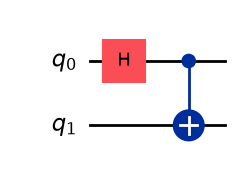

In [5]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
phi_plus = Statevector(bell)
print("amplitudes:", np.round(phi_plus.data, 4))
print("equals (|00> + |11>)/sqrt2?", phi_plus.equiv(Statevector(np.array([1, 0, 0, 1]) / np.sqrt(2))))
bell.draw("mpl")

## 4.5 Product states and entangled states

A two-qubit state is a **product state** if it can be written as $|a\rangle\otimes|b\rangle$ for some single-qubit states. Then each qubit has a state of its own. A state that is **not** a product state is **entangled**.

**A test for two-qubit pure states.** Write $|a\rangle = (a_0, a_1)$ and $|b\rangle = (b_0, b_1)$. A product state has $\alpha_{jk} = a_j b_k$, so

$$
\alpha_{00}\alpha_{11} - \alpha_{01}\alpha_{10} = a_0b_0a_1b_1 - a_0b_1a_1b_0 = 0 .
$$

The converse also holds: if $\alpha_{00}\alpha_{11} = \alpha_{01}\alpha_{10}$ then the state is a product (H1). So the state is entangled exactly when $\alpha_{00}\alpha_{11} - \alpha_{01}\alpha_{10} \neq 0$.

### Worked example 4.2

- $\frac{1}{\sqrt2}(|00\rangle + |01\rangle)$: $\alpha_{00}\alpha_{11} - \alpha_{01}\alpha_{10} = 0 - 0 = 0$. Product: it is $|0\rangle\otimes|+\rangle$.
- $|\Phi^+\rangle$: $\frac{1}{\sqrt2}\cdot\frac{1}{\sqrt2} - 0 = \frac12 \neq 0$. Entangled.

> **Common mistake.** Thinking that any superposition of two qubits is entangled. $\frac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle) = |+\rangle\otimes|+\rangle$ is a superposition of all four basis states but is a product state.

For an entangled state, neither qubit has a pure state of its own. Measure qubit 0 of $|\Phi^+\rangle$ and you get 0 or 1 with probability $\frac12$; whatever you get, qubit 1 then gives the same value. Describing a single qubit of an entangled pair needs density matrices (Workbook 10).

## 4.6 Entanglement versus classical correlation

Run the Bell circuit and measure both qubits in the Z basis. The histogram shows only `00` and `11`, about half each. Does that prove entanglement? **No.** A classical machine that flips a coin and then prepares $|00\rangle$ or $|11\rangle$ gives the same histogram. The two qubits are perfectly correlated in both cases.

Bell state, ZZ: {'00': 997, '11': 1003}
Coin mixture, ZZ: {'00': 989, '11': 1011}


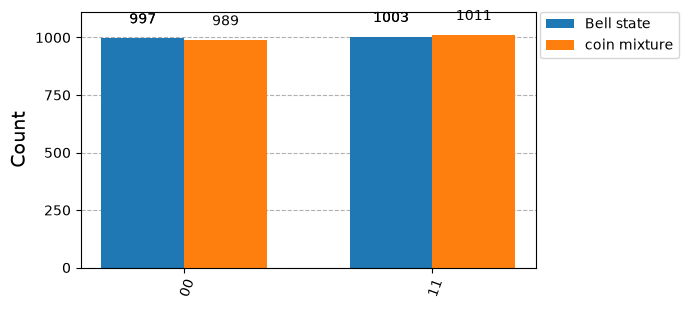

In [6]:
from qiskit_aer.primitives import SamplerV2 as Sampler
from qiskit.visualization import plot_histogram

seed_source = np.random.default_rng(2027)

def run_counts(qc, shots=1000):
    """Run qc on the Aer simulator (not hardware) and return counts."""
    sampler = Sampler(seed=int(seed_source.integers(1_000_000)))
    return sampler.run([qc], shots=shots).result()[0].data.meas.get_counts()

def measured(qc, basis="ZZ"):
    """Copy of qc measured in the Z or X basis on each qubit. basis[0] is q1, basis[1] is q0."""
    m = qc.copy()
    for qubit, b in zip([1, 0], basis):
        if b == "X":
            m.h(qubit)
    m.measure_all()
    return m

def prep_basis(label):
    qc = QuantumCircuit(2)
    for qubit, bit in zip([1, 0], label):
        if bit == "1":
            qc.x(qubit)
    return qc

def coin_mixture(basis, shots):
    """Classical correlation: a coin picks |00> or |11> for each shot."""
    n00 = int(np.random.default_rng(int(seed_source.integers(1_000_000))).binomial(shots, 0.5))
    total = {}
    for label, n in [("00", n00), ("11", shots - n00)]:
        for k, v in run_counts(measured(prep_basis(label), basis), n).items():
            total[k] = total.get(k, 0) + v
    return total

bell_zz = run_counts(measured(bell, "ZZ"), 2000)
coin_zz = coin_mixture("ZZ", 2000)
print("Bell state, ZZ:", dict(sorted(bell_zz.items())))
print("Coin mixture, ZZ:", dict(sorted(coin_zz.items())))
plot_histogram([bell_zz, coin_zz], legend=["Bell state", "coin mixture"], figsize=(7, 3.2))

To tell them apart we must measure in **another basis**. Since $H\otimes H$ maps $|\Phi^+\rangle$ to itself (try it, or see H3), the Bell state is also perfectly correlated in the X basis:

$$
|\Phi^+\rangle = \tfrac{1}{\sqrt2}\left(|00\rangle + |11\rangle\right) = \tfrac{1}{\sqrt2}\left(|{+}{+}\rangle + |{-}{-}\rangle\right).
$$

The coin mixture is not. Each of its shots is $|00\rangle$ or $|11\rangle$, and measuring $|0\rangle$ or $|1\rangle$ in the X basis gives a random result. So in the X basis its two qubits are uncorrelated.

A neat way to summarise this is with **correlations**. For a pair of outcomes $\pm1$ (0 counts as $+1$ and 1 as $-1$), the correlation $\langle Z\otimes Z\rangle$ is the average of the product of the two outcomes. It can be estimated from counts:

$$
\langle Z\otimes Z\rangle \approx \frac{N_{\text{same}} - N_{\text{different}}}{N}.
$$

$\langle X\otimes X\rangle$ is the same thing measured in the X basis. For $|\Phi^+\rangle$ both are $+1$. For the coin mixture, $\langle Z\otimes Z\rangle = 1$ but $\langle X\otimes X\rangle = 0$.

**An entanglement check.** For any product state, and any classical mixture of product states, one can prove (H2)

$$
\lvert\langle X\otimes X\rangle\rvert + \lvert\langle Z\otimes Z\rangle\rvert \leq 1 .
$$

$|\Phi^+\rangle$ gives $2$. So a measured value clearly above $1$ (allowing for shot noise) shows that the two-qubit state is entangled.

In [7]:
def correlation(counts):
    n = sum(counts.values())
    same = sum(v for k, v in counts.items() if k[0] == k[1])
    return (same - (n - same)) / n

shots = 4000
rows = {
    "Bell state": (run_counts(measured(bell, "ZZ"), shots), run_counts(measured(bell, "XX"), shots)),
    "coin mixture": (coin_mixture("ZZ", shots), coin_mixture("XX", shots)),
}
print(f"{'':14s} <ZZ>     <XX>    |<XX>| + |<ZZ>|")
for name, (czz, cxx) in rows.items():
    zz, xx = correlation(czz), correlation(cxx)
    print(f"{name:14s} {zz:+.3f}   {xx:+.3f}   {abs(zz) + abs(xx):.3f}")

               <ZZ>     <XX>    |<XX>| + |<ZZ>|
Bell state     +1.000   +1.000   2.000
coin mixture   +1.000   -0.024   1.024


> **Note.** What this check does and does not show. It assumes we really have two qubits and that the X and Z measurements are what we think they are. Under those assumptions, a value above 1 shows entanglement. It is **not** a Bell test: it does not rule out every possible classical explanation of the data. The CHSH test in Workbook 5 does that, using more measurement settings. And here everything ran on a simulator, so it checks our circuit and our reasoning, not a physical device.

**No signalling.** Entanglement gives correlations, not a communication channel. If Alice measures her qubit of $|\Phi^+\rangle$ in any basis, Bob's qubit on its own still gives 0 or 1 with probability $\frac12$ in the Z basis. He sees the correlation only when they compare results over an ordinary channel (H4).

### Summary

- Two qubits: four amplitudes, ordered $|q_1q_0\rangle$ as in Qiskit (qubit 0 is the rightmost bit).
- A gate on qubit 0 alone is $I\otimes U$; on qubit 1 alone it is $U\otimes I$.
- $\mathrm{CX}_{c\to t}$: $|c\rangle|t\rangle \mapsto |c\rangle|t\oplus c\rangle$. Its matrix depends on the ordering convention.
- $H$ on $q_0$ then $\mathrm{CX}_{0\to1}$ turns $|00\rangle$ into $|\Phi^+\rangle = \frac{1}{\sqrt2}(|00\rangle + |11\rangle)$.
- A pure two-qubit state is entangled exactly when $\alpha_{00}\alpha_{11} - \alpha_{01}\alpha_{10} \neq 0$.
- A Z-basis histogram of `00` and `11` does not prove entanglement. Correlations in two bases can: $\lvert\langle XX\rangle\rvert + \lvert\langle ZZ\rangle\rvert > 1$.

### References for this workbook

- J. D. Hidary, *Quantum Computing: An Applied Approach*, 2nd ed. (Springer, 2021): Ch. 1, Sec. 1.1 (superposition and entanglement); Ch. 3, Sec. 3.1 (binary operators); Ch. 6, Sec. 6.7 (Bell states, in code); Ch. 11, Sec. 11.5 and Ch. 12, Sec. 12.7 (the tensor product); Ch. 7, Sec. 7.4 (Bell inequality test, for Workbook 5).
- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. (Cambridge, 2010): Secs. 1.2.1 (multiple qubits), 1.3.2 (multiple qubit gates), 1.3.6 (Bell states); Secs. 2.1.7 (tensor products) and 2.2.8 (composite systems); Sec. 4.3 (controlled operations); Sec. 2.6 (EPR and the Bell inequality, for later).
- Y. Ding and F. T. Chong, *Quantum Computer Systems* (2020): Ch. 2, Secs. 2.1 and 2.2.
- J. Watrous, IBM Quantum Learning, *Basics of Quantum Information*, Lesson 2 "Multiple systems" and Lesson 3 "Quantum circuits".
- Qiskit Textbook (legacy, archived 2024): chapter "Multiple Qubits and Entanglement", section "Multiple Qubits and Entangled States". Its code uses older Qiskit APIs.

# Part B: Workbook exercises

E = easy, M = medium, H = hard, Q = Qiskit task. Use the $|q_1q_0\rangle$ ordering throughout.

## Easy

**E1.** Write $|10\rangle$ and $|-\rangle\otimes|1\rangle$ as column vectors in $\mathbb{C}^4$.

**E2.** Start in $|00\rangle$ and apply $X$ to qubit 0. Which bit string do you measure? Write the state as a ket and as a Qiskit label.

**E3.** Apply $\mathrm{CX}_{0\to1}$ to $|01\rangle$ and to $|10\rangle$.

**E4.** Is $\frac{1}{\sqrt2}(|10\rangle + |11\rangle)$ entangled? If not, write it as a product.

**E5.** Write the amplitudes of $|\Psi^-\rangle$ in the order $00, 01, 10, 11$ and check that it is normalised.

**E6.** (Conceptual.) A student runs the Bell circuit on a simulator, sees only `00` and `11` and writes "this proves the qubits are entangled". Give two reasons why this claim is too strong.

## Medium

**M1.** Compute $\langle\Phi^+|\Phi^-\rangle$, $\langle\Phi^+|\Psi^+\rangle$ and $\langle\Psi^+|\Psi^+\rangle$.

**M2.** Use the test $\alpha_{00}\alpha_{11} - \alpha_{01}\alpha_{10}$ to decide which states are entangled:
(a) $\frac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle)$, (b) $\frac12(|00\rangle + |01\rangle + |10\rangle - |11\rangle)$, (c) $\frac15(3|00\rangle + 4|11\rangle)$.

**M3.** Work through the circuit "$H$ on $q_0$, then $\mathrm{CX}_{0\to1}$" for the inputs $|01\rangle$, $|10\rangle$ and $|11\rangle$, and confirm the table in Section 4.4.

**M4.** For $|\psi\rangle = \frac{1}{\sqrt3}(|00\rangle + |01\rangle + |11\rangle)$, find $P(q_0 = 1)$. If the outcome is $q_0 = 1$, what is the state afterwards? Is it a product state?

**M5.** Find $\langle Z\otimes Z\rangle$ and $\langle X\otimes X\rangle$ for $|\Psi^+\rangle$. (Hint: $|\Psi^+\rangle$ is $(X\otimes I)|\Phi^+\rangle$.) Does it pass the entanglement check of Section 4.6?

**M6.** Show that $(H\otimes H)\,\mathrm{CX}_{0\to1}\,(H\otimes H) = \mathrm{CX}_{1\to0}$. (You may multiply the $4\times4$ matrices in Python.) In words: what happens to "control" and "target" in the X basis?

## Hard

**H1.** Show the converse of the product-state test: if $\alpha_{00}\alpha_{11} = \alpha_{01}\alpha_{10}$, the state is a product $|a\rangle\otimes|b\rangle$. (Hint: if $\alpha_{00} \neq 0$, try $|a\rangle \propto (\alpha_{00}, \alpha_{10})$ and $|b\rangle \propto (\alpha_{00}, \alpha_{01})$; handle $\alpha_{00} = 0$ separately.)

**H2.** For a product state $|a\rangle\otimes|b\rangle$, show that $\langle X\otimes X\rangle = x_ax_b$ and $\langle Z\otimes Z\rangle = z_az_b$, where $(x_a, y_a, z_a)$ and $(x_b, y_b, z_b)$ are the Bloch vectors. Use the Cauchy-Schwarz inequality to show $\lvert x_ax_b\rvert + \lvert z_az_b\rvert \leq 1$. Explain why the bound also holds for a classical mixture of product states.

**H3.** Show that $|\Phi^+\rangle = \frac{1}{\sqrt2}(|{+}{+}\rangle + |{-}{-}\rangle)$ and that $(H\otimes H)|\Phi^+\rangle = |\Phi^+\rangle$.

**H4.** (No signalling.) Alice holds qubit 1 and Bob holds qubit 0 of $|\Phi^+\rangle$. Alice either does nothing, or applies $H$ to her qubit and measures it. Show that in both cases Bob's Z-basis outcome is 0 with probability $\frac12$.

## Qiskit tasks

**Q1.** Build the circuit "$H$ on $q_0$, then $\mathrm{CX}_{0\to1}$" for each of the four basis inputs (use `prep_basis`). Use `Statevector(...).equiv(...)` to confirm each output is the Bell state in the table of Section 4.4.

In [8]:
# Q1: your code here

**Q2.** Check the CNOT truth table on the simulator: for each input label, run 500 shots of `prep_basis(label)` followed by `cx(0, 1)` and measurement. Then repeat with `cx(1, 0)` and check it against $\mathrm{CX}_{1\to0}$.

In [9]:
# Q2: your code here

**Q3.** Prepare $|\Psi^+\rangle$. Estimate $\langle Z\otimes Z\rangle$ and $\langle X\otimes X\rangle$ from 4000 shots each, using `measured` and `correlation`. Compare with your answer to M5 and compute $\lvert\langle XX\rangle\rvert + \lvert\langle ZZ\rangle\rvert$.

In [10]:
# Q3: your code here

# Part C: Answer key

The answer key is in the instructor edition of this workbook.